# 08 - Explainable AI (TreeSHAP) & VUS Prioritization Index
**Project**: AI-Based Structural Variant Prioritization from Long-Read Sequencing Using Explainable Machine Learning  
**Author**: Data Science & Genomics Team  
**Date**: August 2026

## Objective
1. Compute **TreeSHAP feature attributions** to explain model predictions globally and locally.
2. Apply the trained model to all **34,466 Variants of Uncertain Significance (VUS)**.
3. Classify VUS into clinical prioritization tiers and inspect top high-risk candidates for diagnostic follow-up.


In [1]:
import os

def resolve_path(p):
    for candidate in [p, os.path.join("..", p), os.path.join("data", p), os.path.join("..", "data", p)]:
        if os.path.exists(candidate):
            return candidate
    return p

import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

test_path = resolve_path("processed/test.csv.gz")
vus_path = resolve_path("processed/vus_inference.csv.gz")
model_path = resolve_path("models/xgboost_model.joblib")
if not os.path.exists(model_path):
    model_path = resolve_path("../models/xgboost_model.joblib")

df_test = pd.read_csv(test_path)
df_vus = pd.read_csv(vus_path)
xgb_model = joblib.load(model_path)

exclude_cols = ["variation_id", "chrom", "start", "stop", "clinical_class", "assembly", "target"]
feature_cols = [c for c in df_test.columns if c not in exclude_cols]

X_test = df_test[feature_cols]
X_vus = df_vus[feature_cols]

print(f"Loaded X_test ({X_test.shape}) and X_vus ({X_vus.shape}).")


Loaded X_test ((8854, 24)) and X_vus ((34466, 24)).


## 1. TreeSHAP Global Feature Attribution (Beeswarm Plot)

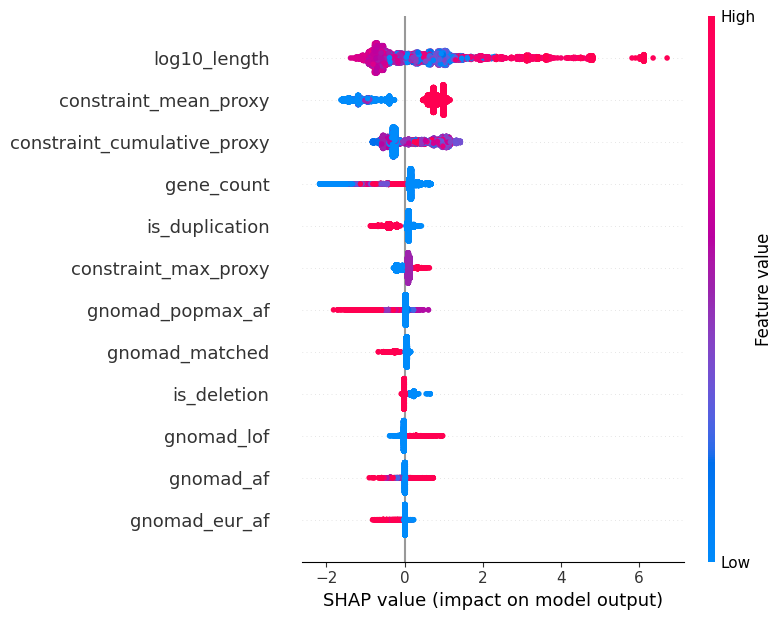

In [2]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test)

# Plot Beeswarm Summary directly with shap.summary_plot
shap.summary_plot(shap_values.values, X_test, max_display=12, show=True)


### Global Feature Importance Bar Chart

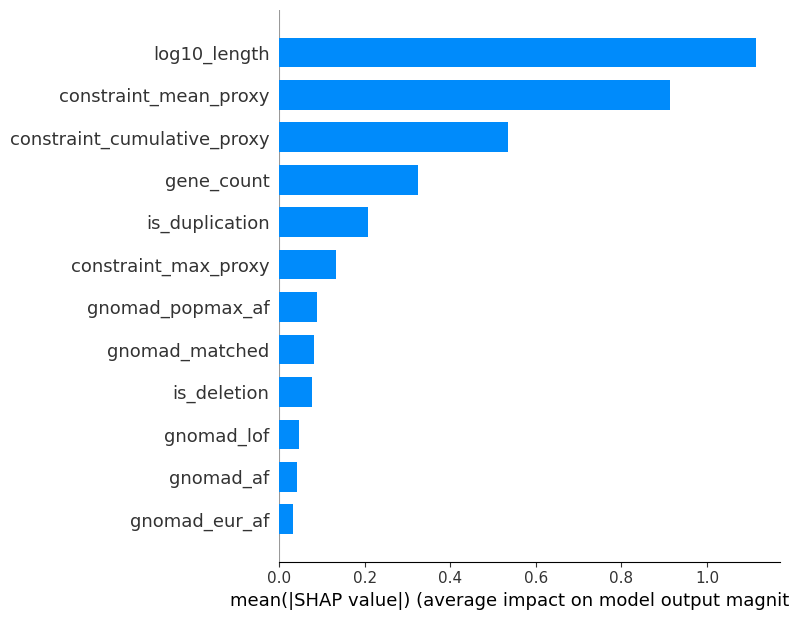

In [3]:
# Plot Feature Importance Bar Chart
shap.summary_plot(shap_values.values, X_test, plot_type="bar", max_display=12, show=True)


## 2. Prioritize 34,466 Variants of Uncertain Significance (VUS)

VUS Triage Breakdown:
  Tier 4: High-Confidence Likely Benign Polymorphism: 15,927 (46.2%)
  Tier 3: Low-Risk Likely Tolerated: 7,819 (22.7%)
  Tier 2: Moderate-Risk Potential Deleterious: 6,883 (20.0%)
  Tier 1: High-Confidence Pathogenic Candidate: 3,837 (11.1%)


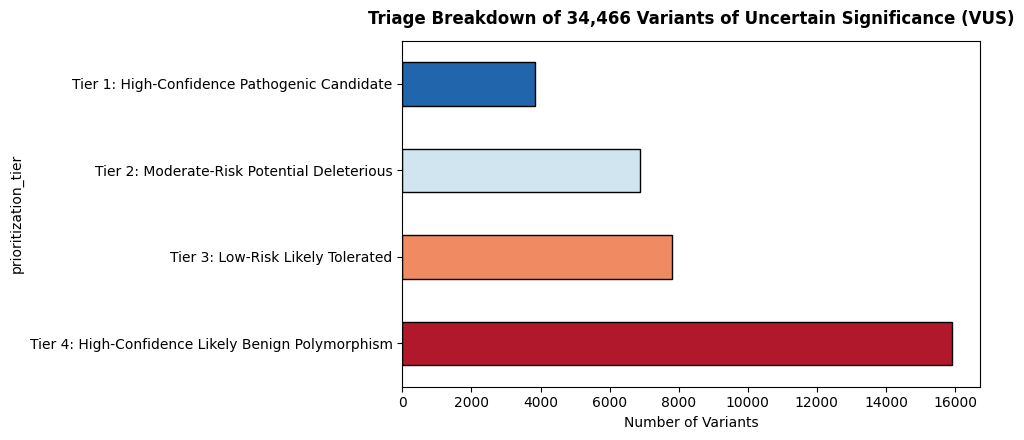

In [4]:
vus_probs = xgb_model.predict_proba(X_vus)[:, 1]
df_vus["predicted_pathogenicity_score"] = vus_probs

def assign_tier(p):
    if p >= 0.85:
        return "Tier 1: High-Confidence Pathogenic Candidate"
    elif p >= 0.50:
        return "Tier 2: Moderate-Risk Potential Deleterious"
    elif p >= 0.20:
        return "Tier 3: Low-Risk Likely Tolerated"
    else:
        return "Tier 4: High-Confidence Likely Benign Polymorphism"

df_vus["prioritization_tier"] = df_vus["predicted_pathogenicity_score"].apply(assign_tier)
df_vus_sorted = df_vus.sort_values(by="predicted_pathogenicity_score", ascending=False).reset_index(drop=True)

tier_counts = df_vus_sorted["prioritization_tier"].value_counts()
print("VUS Triage Breakdown:")
for tier, count in tier_counts.items():
    print(f"  {tier}: {count:,} ({count/len(df_vus)*100:.1f}%)")

plt.figure(figsize=(10, 4.5))
tier_counts.plot(kind="barh", color=["#b2182b", "#ef8a62", "#d1e5f0", "#2166ac"], edgecolor="black")
plt.title("Triage Breakdown of 34,466 Variants of Uncertain Significance (VUS)", fontweight="bold", pad=12)
plt.xlabel("Number of Variants")
plt.tight_layout()
plt.show()


## 3. Top 20 Highest Priority VUS Candidates for Clinical Diagnostic Review

In [5]:
display_cols = [
    "variation_id", "chrom", "start", "stop", "log10_length", "gene_count",
    "is_deletion", "gnomad_af", "predicted_pathogenicity_score", "prioritization_tier"
]
df_vus_sorted[display_cols].head(20)


,variation_id,chrom,start,stop,log10_length,gene_count,is_deletion,gnomad_af,predicted_pathogenicity_score,prioritization_tier
0,221357,1,909238,16736132,7.199396,1,0,0.0,0.999225,Tier 1: High-Confidence Pathogenic Candidate
1,221334,1,909238,24706269,7.376523,1,0,0.0,0.999225,Tier 1: High-Confidence Pathogenic Candidate
2,221369,12,10074776,18800953,6.940824,1,0,0.0,0.999152,Tier 1: High-Confidence Pathogenic Candidate
3,4682834,13,75417697,93784678,7.264038,1,1,0.0,0.998771,Tier 1: High-Confidence Pathogenic Candidate
4,1711170,6,78911022,98909173,7.300990,1,1,0.0,0.998771,Tier 1: High-Confidence Pathogenic Candidate
5,1340004,11,85422071,118022671,7.513226,1,1,0.0,0.998771,Tier 1: High-Confidence Pathogenic Candidate
6,560111,7,73591993,93683437,7.303011,1,1,0.0,0.998771,Tier 1: High-Confidence Pathogenic Candidate
7,3392397,13,50232243,65699459,7.189412,1,1,0.0,0.998771,Tier 1: High-Confidence Pathogenic Candidate
8,221523,16,55359026,70884455,7.191044,1,1,0.0,0.998771,Tier 1: High-Confidence Pathogenic Candidate
9,221527,16,72107834,90142285,7.256103,1,1,0.0,0.998771,Tier 1: High-Confidence Pathogenic Candidate
